In [79]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import data_preprocessing.plotting_functions as ABC_plot
import data_preprocessing.ABC_priors_and_functions as ABC
import data_preprocessing.stochastic_systems_models as SSM

SMALL_SIZE = 12
MEDIUM_SIZE = 12
BIGGER_SIZE = 16

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rcParams['font.family'] = 'Arial'

In [80]:
#Extracting posterior parameters
params = np.load("C:\\Uni\\Imperial\\Year 1\\First_pet_project\\Project4\\extended_three_pop_ABC\\accepted_extended_three_population_chase_pulse_params.npy")
beta0, beta1, p, mu_d_r, mu_d_y, mu_d_o, mu_a, mu_r, mu_rej, c = params.transpose()

mu_b = np.zeros(len(beta0))
mu_b[mu_d_o != 0] = ((mu_d_r+p*mu_r)*(mu_d_y*mu_d_o + mu_d_y*mu_rej+mu_d_o*mu_a)/((mu_d_o+mu_rej)*(mu_r-mu_d_r)))[mu_d_o != 0]
mu_b[mu_d_o == 0] = ((mu_d_r+p*mu_r)*mu_d_y/(mu_r-mu_d_r))[mu_d_o == 0]

f_y = 1/(1 + mu_b/(mu_d_r + p*mu_r) + mu_a/(mu_d_o + mu_rej))
f_r = (mu_b/(mu_d_r + p*mu_r))*1/(1 + mu_b/(mu_d_r + p*mu_r) + mu_a/(mu_d_o + mu_rej))
f_o = 1-f_y-f_r

pi_y = 1/(1 + (1+p)*mu_b*mu_r/(mu_d_r+p*mu_r)**2 + mu_a*mu_rej/(mu_d_o + mu_rej)**2)

mu_coal =  2 * (pi_y/f_y)**2 * f_r * (mu_r + mu_d_r*p)/(mu_r*p + mu_d_r) * mu_r

m = mu_rej/(mu_rej+mu_d_o)

The following codeblocks includes all of the choices in parameters for the bottlenecks of the main text. Run the first codeblock to set the starting parameteriation, then whichever subsequent codeblock you wish to set the parameters you are bottlecking.

In [81]:
#-----------------------original parameterisation with inactive degradation (RUN THIS CODEBLOCK)--------------------------#
param = params[35]

Run only one of the next four blocks

In [ ]:
#-------------------------mu_a alteration --------------------------------# 
#mu_a: 0.22 -> 1
altered_param = param*1
altered_param[6] = 1
altered_mu_b = False

In [ ]:
#-------------------------mu_a' alteration --------------------------------#
#mu_a': 0.03 -> 0.008
altered_param = param*1
altered_param[8] = 0.008
altered_mu_b = False

In [ ]:
#-------------------------mu_a and mu_a' alteration --------------------------------#
#mu_a: 0.22 -> 1
#mu_a': 0.03 -> 0.008
altered_param = param*1
altered_param[6] = 1
altered_param[8] = 0.008
altered_mu_b = False

In [82]:
#-----------same classical subfactors (N and mu_turn), but altered subpopulation subfactors (f_a, m_q) (see supplement)------------#
#mu_a': 0.03 -> 0
#mu_{d,q}: 0.027 -> 0.021
#mu_b will be adjusted to maintain copy number control (N) in the stochastic simulator by setting altered_mu_b=True
mu_turn = f_r[35]*mu_r[35]
altered_param = param*1
altered_param[8] = 0
altered_param[5] = mu_turn/(1-mu_turn*(1/mu_r[35] + 1/mu_a[35]))
altered_mu_b = True

We first repeatedly pulse this selected parameter bottleneck

In [83]:
cSFS, replicating_mutants, young_mutants, old_mutants, f_as, f_qs, Ns, mu_turns, = SSM.extended_three_population_pulsing_forward_coalescent(param, altered_param, pulsing_freq=6/(365), pulsing_length=2/365, track_every = 1/(365*24*2), truncation_time = 5*7/365, pulsing_stagger = -2/365, N=500, mutation_probability = 0.05, altered_mu_b=altered_mu_b)

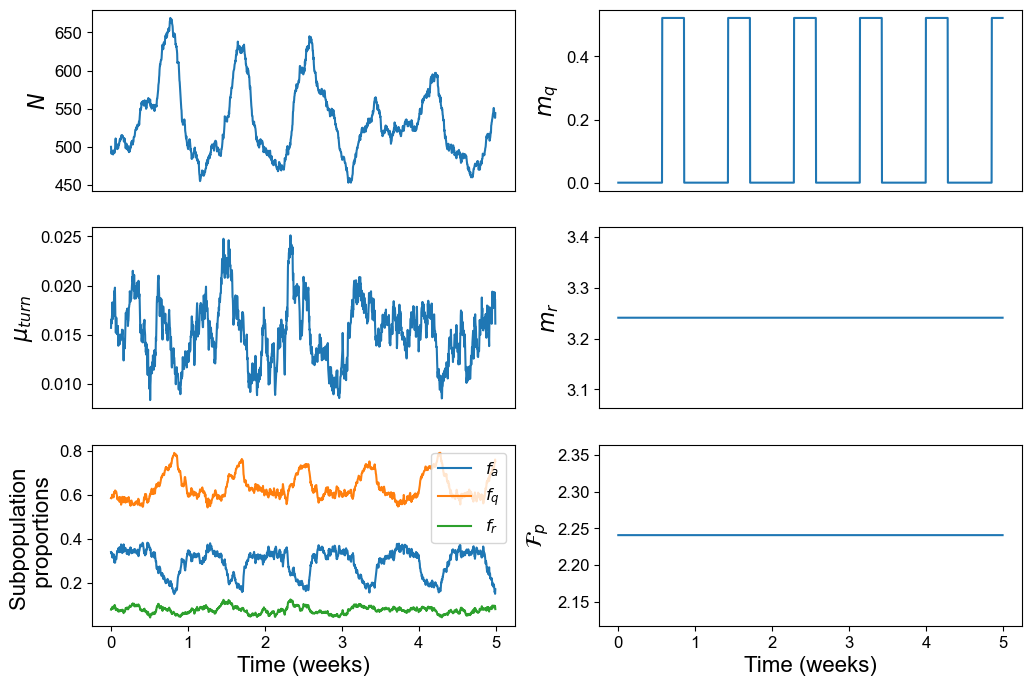

In [84]:
def plot_subpopulation_bottleneck(param, altered_param, pulsing_freq, pulsing_length, track_every, truncation_time, pulsing_stagger, f_ys, f_qs, Ns, mu_turns, timescale = "weeks"):
    
    m_qs = []
    m_rs = []
    pref_facs = []

    for current_time in np.arange(0,truncation_time*24*365, track_every*24*365):
        if (current_time-pulsing_stagger*24*365)%(pulsing_freq*24*365) < pulsing_length*24*365:
            beta0, beta1, p, mu_d_r, mu_d_y, mu_d_o, mu_a, mu_r, mu_rej, c = param
        else:
            beta0, beta1, p, mu_d_r, mu_d_y, mu_d_o, mu_a, mu_r, mu_rej, c = altered_param
        m_qs.append(mu_rej/(mu_rej+mu_d_o))
        m_rs.append((1+p)*mu_r/(mu_d_r+p*mu_r))
        pref_facs.append((p*mu_d_r+mu_r)/(mu_d_r+p*mu_r))

    if timescale == "weeks":
        scale = 24*7
        xlab = "Time (weeks)"
    elif timescale == "months":
        scale = 24*365/12
        xlab = "Time (months)"

    time = np.arange(0,truncation_time*24*365, track_every*24*365)/scale
    fig, ax = plt.subplots(3,2, figsize = (12,8))
    ax[0,0].plot(time, Ns)
    ax[1,0].plot(time, mu_turns)
    ax[2,0].plot(time, f_ys, label = "$f_a$")
    ax[2,0].plot(time, f_qs, label = "$f_q$")
    ax[2,0].plot(time, 1-f_qs-f_ys, label = "$f_r$")
    ax[2,0].legend()
    ax[0,1].plot(time, m_qs)
    ax[1,1].plot(time, m_rs)
    ax[2,1].plot(time, pref_facs)
    ax[0,0].set_ylabel("$N$")
    ax[1,0].set_ylabel("$\mu_{turn}$")
    ax[2,0].set_ylabel("Subpopulation \n proportions")
    ax[0,1].set_ylabel("$m_q$")
    ax[1,1].set_ylabel("$m_r$")
    ax[2,1].set_ylabel("$\mathcal{F}_p$")
    ax[2,0].set_xlabel(xlab)
    ax[2,1].set_xlabel(xlab)
    ax[0,0].set_xticks([],[])
    ax[1,0].set_xticks([],[])
    ax[0,1].set_xticks([],[])
    ax[1,1].set_xticks([],[])

plot_subpopulation_bottleneck(param, altered_param, pulsing_freq=6/(365), pulsing_length=2/365, track_every = 1/(365*24*2), truncation_time = 5*7/365, pulsing_stagger = -2/365, f_ys=f_as, f_qs=f_qs, Ns=Ns, mu_turns=mu_turns, timescale = "weeks")

    

Now we create a sustained mid-life bottleneck

In [85]:
cSFS, replicating_mutants, active_mutants, inactive_mutants, f_as, f_qs, Ns, mu_turns = SSM.extended_three_population_pulsing_forward_coalescent(param, altered_param, pulsing_freq=2, pulsing_length=2/3, track_every = 1/365, truncation_time = 2, pulsing_stagger = 2/3, N=500, mutation_probability = 0.05, altered_mu_b=altered_mu_b)


time: 0.24999892456919237 years
time: 0.499998943237037 years
time: 0.7499942450446059 years
time: 0.9999995124310371 years
time: 1.2499986059708106 years
time: 1.4999992620242866 years
time: 1.749998992956359 years
time: 1.999994212720207 years


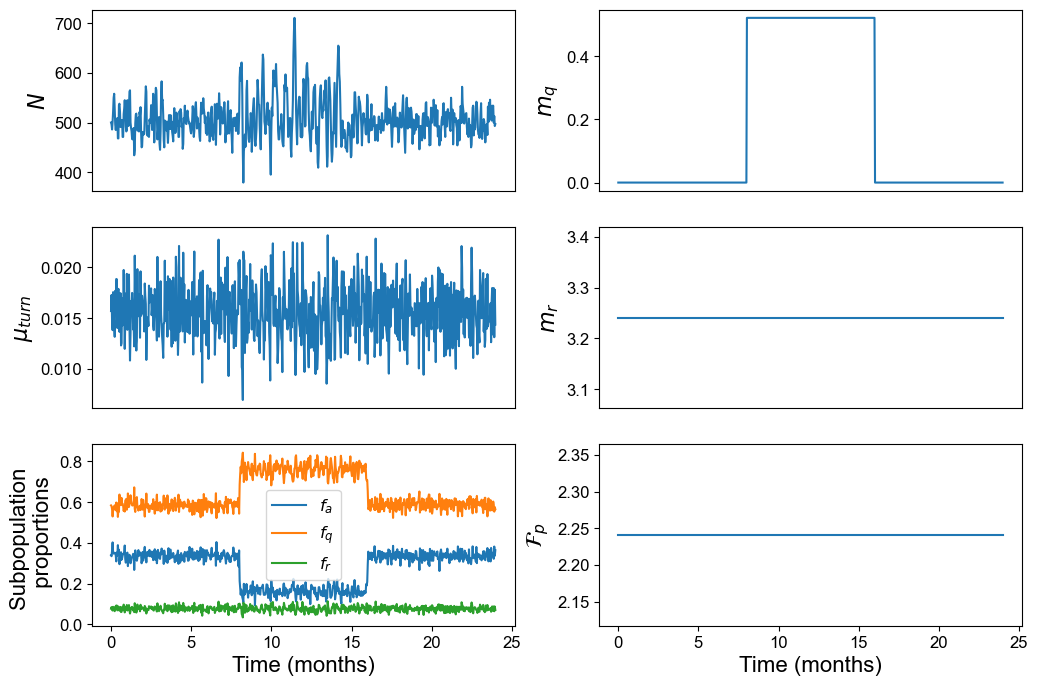

In [86]:
plot_subpopulation_bottleneck(param, altered_param, pulsing_freq=2, pulsing_length=2/3, track_every = 1/365, truncation_time = 2, pulsing_stagger = 2/3, f_ys=f_as, f_qs=f_qs, Ns=Ns, mu_turns=mu_turns, timescale = "months")

The following codeblock includes all of the choices in parameters for the bottlenecks of the supplement. Uncomment whichever parameter you wish to alter.

In [87]:
#-------------------------original parameterisation with equiprobable degradation------------------------------------#
param = params[180]
altered_mu_b = False

#-----------------------parameterisations with one parameter altered------------------#

# #p: 0.39 -> 0.8
# altered_param = param*1
# altered_param[2] = 0.8

# #mu_{d,r}: 0.02 -> 0.08
# altered_param = param*1
# altered_param[3] = 0.08

# #mu_{d,a}: 0.02 -> 0.08
# altered_param = param*1
# altered_param[4] = 0.08

# #mu_{d,q}: 0.02 -> 0.08
altered_param = param*1
altered_param[5] = 0.08

# #mu_r: 0.3 -> 0.1
# altered_param = param*1
# altered_param[7] = 0.1

# #mu_a: 0.55 -> 2
# altered_param = param*1
# altered_param[6] = 2

# #mu_a': 0.18 -> 0.03
# altered_param = param*1
# altered_param[8] = 0.03

Pulsed bottleneck:

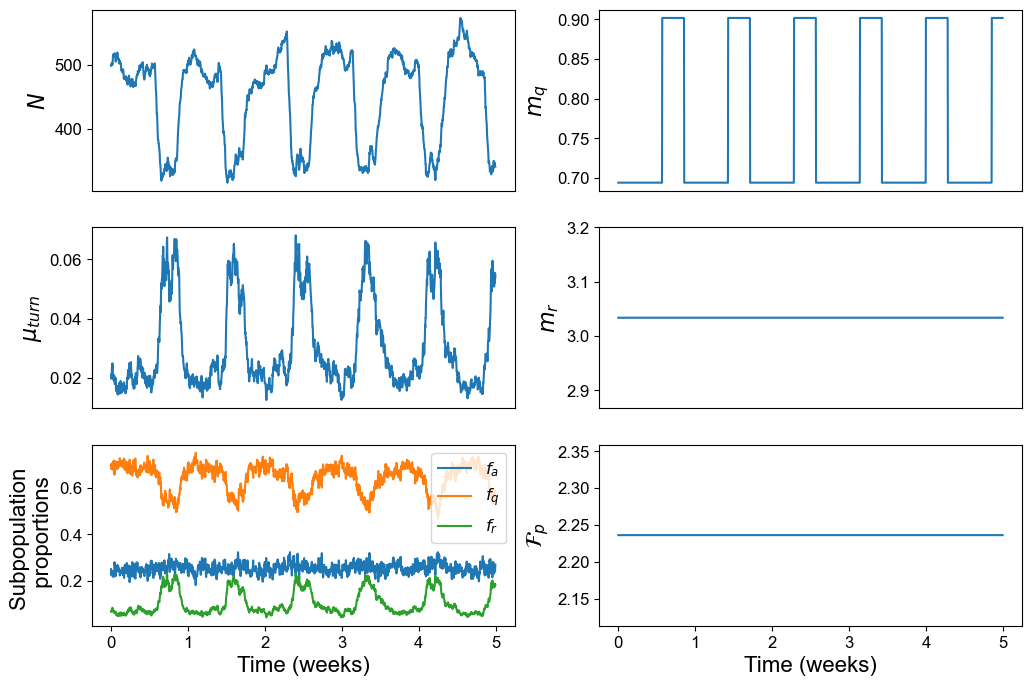

In [88]:
cSFS, replicating_mutants, young_mutants, old_mutants, f_as, f_qs, Ns, mu_turns, = SSM.extended_three_population_pulsing_forward_coalescent(param, altered_param, pulsing_freq=6/(365), pulsing_length=2/365, track_every = 1/(365*24*2), truncation_time = 5*7/365, pulsing_stagger = -2/365, N=500, mutation_probability = 0.05, altered_mu_b=altered_mu_b)

plot_subpopulation_bottleneck(param, altered_param, pulsing_freq=6/(365), pulsing_length=2/365, track_every = 1/(365*24*2), truncation_time = 5*7/365, pulsing_stagger = -2/365, f_ys=f_as, f_qs=f_qs, Ns=Ns, mu_turns=mu_turns, timescale = "weeks")

Sustained bottleneck (note: for some choices of parameterisations, this can take up to 10 minutes)

time: 0.24999954834082025 years
time: 0.4999999869539691 years
time: 0.7499996065292812 years
time: 0.9999998518066355 years
time: 1.2499976376769253 years
time: 1.4999999203089478 years
time: 1.7499999821565144 years
time: 1.9999982291471559 years


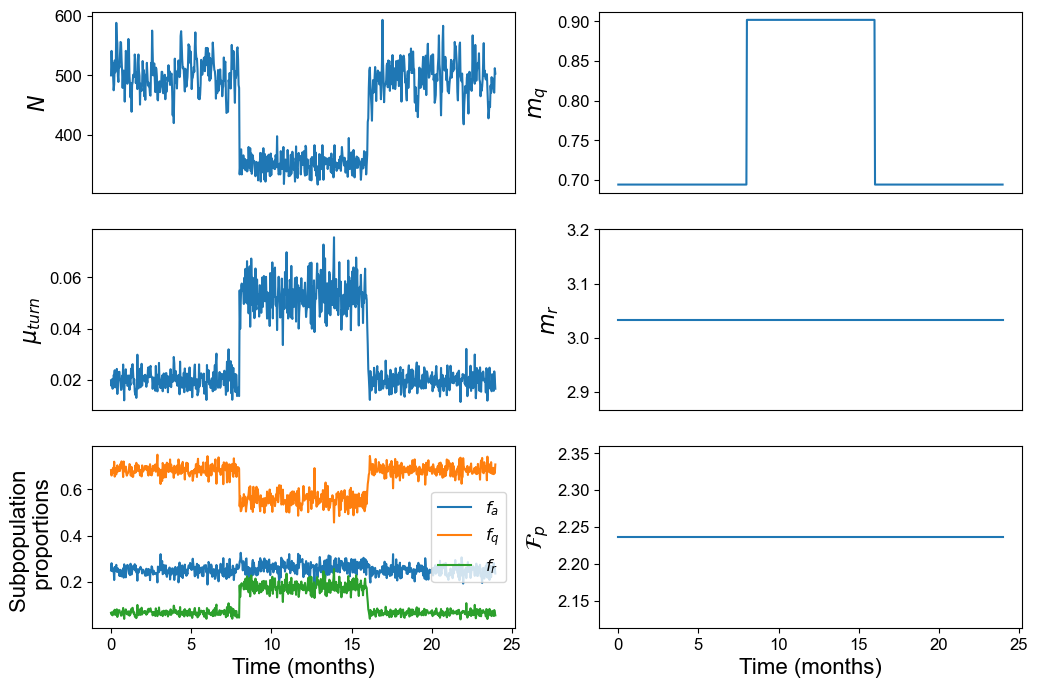

In [89]:
cSFS, replicating_mutants, active_mutants, inactive_mutants, f_as, f_qs, Ns, mu_turns = SSM.extended_three_population_pulsing_forward_coalescent(param, altered_param, pulsing_freq=2, pulsing_length=2/3, track_every = 1/365, truncation_time = 2, pulsing_stagger = 2/3, N=500, mutation_probability = 0.05, altered_mu_b=altered_mu_b)

plot_subpopulation_bottleneck(param, altered_param, pulsing_freq=2, pulsing_length=2/3, track_every = 1/365, truncation_time = 2, pulsing_stagger = 2/3, f_ys=f_as, f_qs=f_qs, Ns=Ns, mu_turns=mu_turns, timescale = "months")


The above functions also spawn mutations randomly and output a site frequency spectrum.

Text(0.5, 0, 'Heteroplasmy')

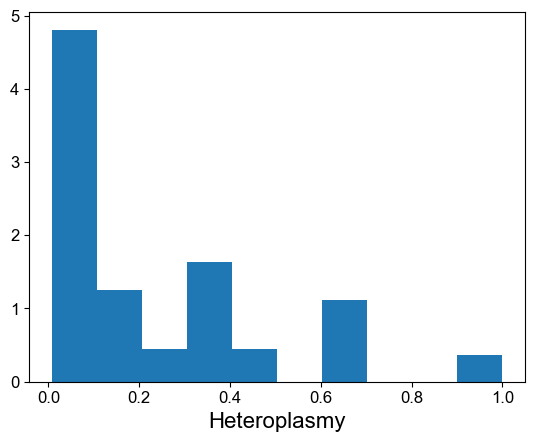

In [90]:
plt.hist(cSFS, density = True)
plt.xlabel("Heteroplasmy")


To obtain a better approximation of the 'true' site frequency spectrum, we must run the above functions multiple times and amalgomate their results into one histogram. Here we display the presaved histograms generated via this process for the above parameter alterations:

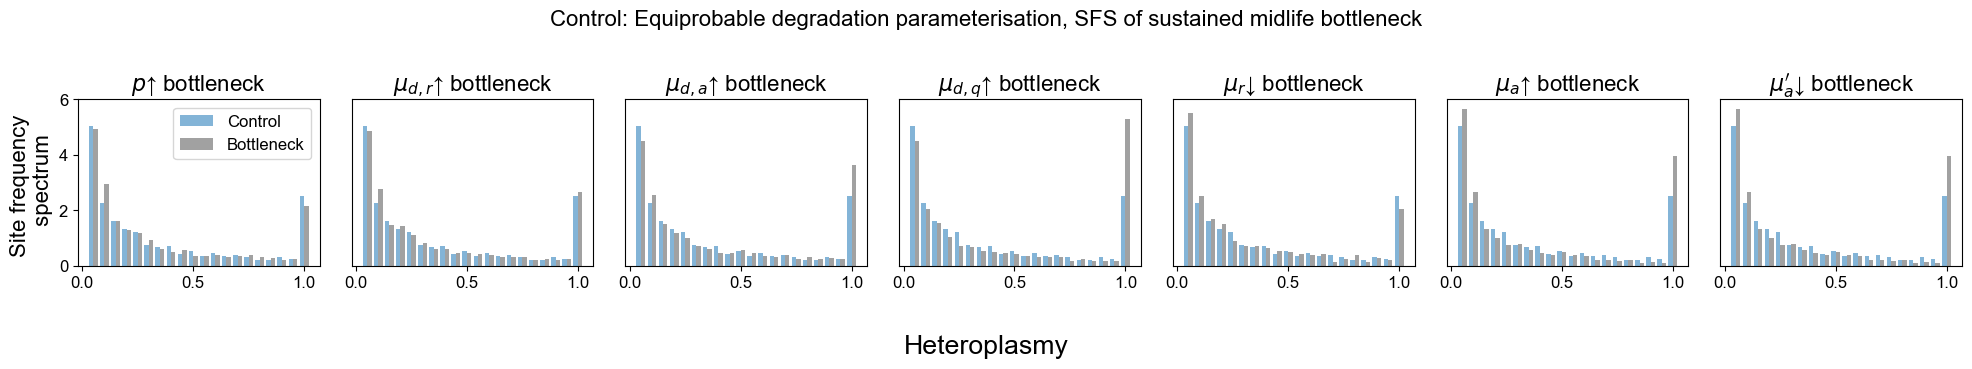

In [91]:
control_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS.npy")
mua_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_mua.npy")
murej_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_murej.npy")
mudo_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_mudo.npy")
mudr_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_mudr.npy")
mudy_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_mudy.npy")
mur_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_mur.npy")
p_SFS = np.load("data_preprocessing/simulated_SFSs/ep180_N500_n20_SFS_p.npy")

cmap = plt.get_cmap('tab20c')

# Extract all 20 colors as hex codes
import matplotlib.colors as mcolors
hex_colors = [mcolors.to_hex(cmap(i)) for i in range(20)]

fig, ax = plt.subplots(1,7, figsize=(20,3.6))
ax[0].hist([control_SFS, p_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)
ax[0].legend()
ax[1].hist([control_SFS, mudr_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)
ax[2].hist([control_SFS, mudy_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)
ax[3].hist([control_SFS, mudo_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)
ax[4].hist([control_SFS, mur_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)
ax[5].hist([control_SFS, mua_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)
ax[6].hist([control_SFS, murej_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Bottleneck"], alpha= 0.6)

ax[0].set_ylabel("Site frequency \n spectrum")
for i in range(7):
    ax[i].set_ylim(0,6)
    if i != 0:
        ax[i].set_yticks([],[])
fig.supxlabel('Heteroplasmy')

ax[0].set_title("$p$↑ bottleneck")
ax[1].set_title("$\mu_{d,r}$↑ bottleneck")
ax[2].set_title("$\mu_{d,a}$↑ bottleneck")
ax[3].set_title("$\mu_{d,q}$↑ bottleneck")
ax[4].set_title("$\mu_r$↓ bottleneck")
ax[5].set_title("$\mu_a$↑ bottleneck")
ax[6].set_title("$\mu_a'$↓ bottleneck")

plt.suptitle("Control: Equiprobable degradation parameterisation, SFS of sustained midlife bottleneck")
plt.tight_layout()



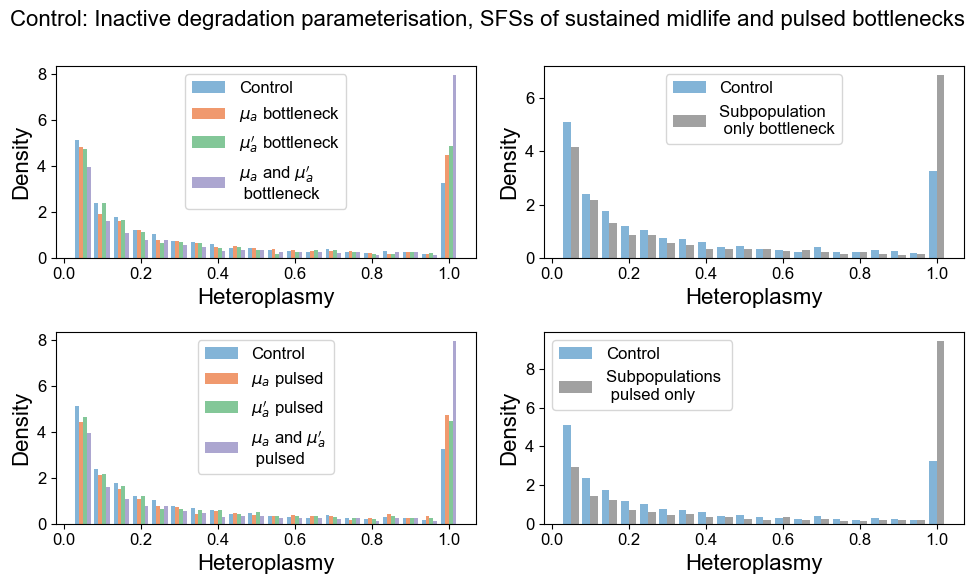

In [92]:
control_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_control_2y.npy")
murej_bottleneck_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_murej_bottleneck_2y3.npy")
mua_bottleneck_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_mua_bottleneck_2y.npy")
murej_sequential_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_murej_sequential_2y3.npy")
mua_sequential_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_mua_sequential_2y.npy")
combined_bottleneck_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_combined_bottleneck_2y.npy")
combined_sequential_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_combined_sequential_2y.npy")
subpop_bottleneck_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_subpop_2y_bottleneck.npy")
subpop_sequential_SFS = np.load("data_preprocessing/simulated_SFSs/ep35_N500_n20_SFS_subpop_2y_sequential.npy")

fig, ax = plt.subplots(2,2, figsize=(10,6))
ax[0,0].hist([control_SFS, mua_bottleneck_SFS, murej_bottleneck_SFS,combined_bottleneck_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[4],hex_colors[8],hex_colors[12]], label = ["Control", "$\mu_a$ bottleneck", "$\mu_a'$ bottleneck", "$\mu_a$ and $\mu_a'$ \n bottleneck"], alpha= 0.6)
ax[0,0].legend()
ax[0,0].set_xlabel("Heteroplasmy")
ax[0,0].set_ylabel("Density")

ax[0,1].hist([control_SFS, subpop_bottleneck_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Subpopulation \n only bottleneck"], alpha= 0.6)
ax[0,1].legend()
ax[0,1].set_xlabel("Heteroplasmy")
ax[0,1].set_ylabel("Density")

ax[1,0].hist([control_SFS, mua_sequential_SFS, murej_sequential_SFS, combined_sequential_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[4],hex_colors[8],hex_colors[12]], label = ["Control", "$\mu_a$ pulsed", "$\mu_a'$ pulsed", "$\mu_a$ and $\mu_a'$ \n pulsed"], alpha= 0.6)
ax[1,0].legend()
ax[1,0].set_xlabel("Heteroplasmy")
ax[1,0].set_ylabel("Density")

ax[1,1].hist([control_SFS, subpop_sequential_SFS], bins = np.arange(0,21)/20 + 0.025, density=True, histtype='bar', color = [hex_colors[0],hex_colors[16]], label = ["Control", "Subpopulations \n pulsed only"], alpha= 0.6)
ax[1,1].legend()
ax[1,1].set_xlabel("Heteroplasmy")
ax[1,1].set_ylabel("Density")

plt.suptitle("Control: Inactive degradation parameterisation, SFSs of sustained midlife and pulsed bottlenecks")
plt.tight_layout()

In the case of the pulsed bottlenecks, we can approximate their SFS with a single coalescent rate SFS; we compute the best fitting coalescent rate using a least squares algorithm:

In [93]:
#MSE function: we will minimise the MSE between the analytic single coalescent rate SFS and the computed SFS for the pulsed parameters
def MSE(analytic_SFS, data):
    a = np.histogram(data, bins = np.arange(0,21)/20 + 0.025)[0]
    return np.mean((a/np.sum(a) - analytic_SFS)**2)

#computing MSE for a sweep of coalescent rate values
mua_MSEs = []
mua_prime_MSEs = []
combined_MSEs = []
subpop_MSEs = []
coals = np.linspace(0.00001,0.001, 50)
for coal in coals:
    mua_MSEs.append(MSE(SSM.expected_SFS(truncation_time=2, n=20, mu_c = coal), mua_sequential_SFS))
    mua_prime_MSEs.append(MSE(SSM.expected_SFS(truncation_time=2, n=20, mu_c = coal), murej_sequential_SFS))
    combined_MSEs.append(MSE(SSM.expected_SFS(truncation_time=2, n=20, mu_c = coal), combined_sequential_SFS))
    subpop_MSEs.append(MSE(SSM.expected_SFS(truncation_time=2, n=20, mu_c = coal), subpop_sequential_SFS))

#finding the coalescent rate that minimises the MSE
mua_pulsed_mu_c = coals[np.argmin(mua_MSEs)]
mua_prime_pulsed_mu_c = coals[np.argmin(mua_prime_MSEs)]
combined_pulsed_mu_c = coals[np.argmin(combined_MSEs)]
subpop_pulsed_mu_c = coals[np.argmin(subpop_MSEs)]


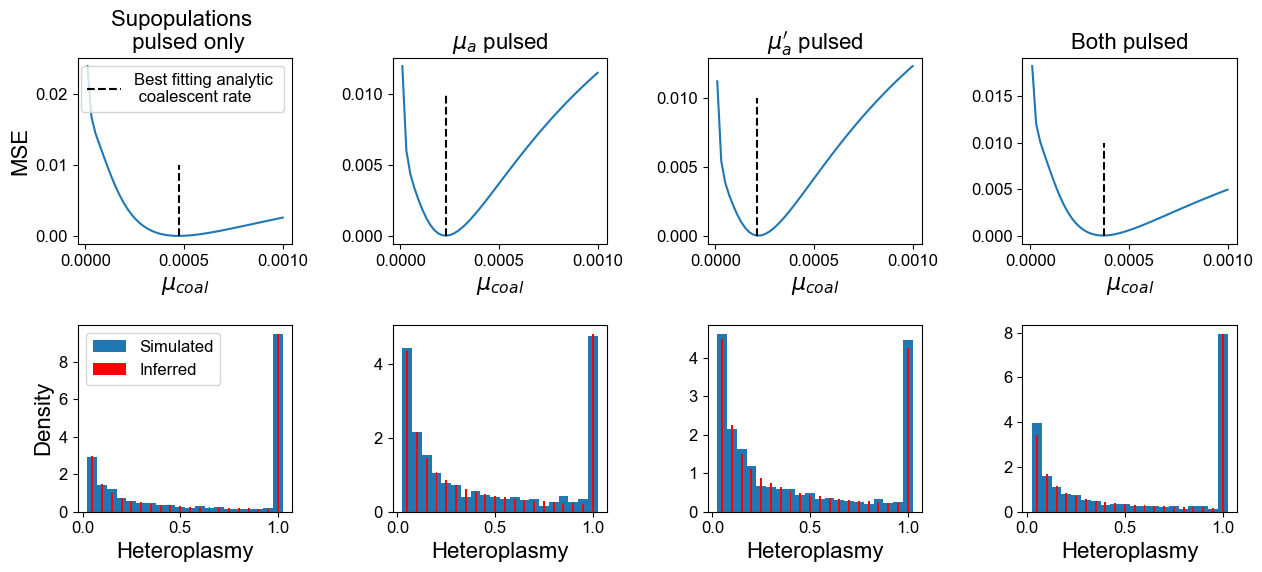

In [95]:
#plotting the MSE curves and their minimumns, and the analytic vs simulated SFSs
fig, ax = plt.subplots(2,4, figsize = (13,6))

ax[0,0].plot(coals, subpop_MSEs)
ax[0,0].vlines(subpop_pulsed_mu_c, 0,0.01, linestyle = "dashed", color = "black", label = "Best fitting analytic \n coalescent rate")
ax[0,0].set_xlabel("$\mu_{coal}$")
ax[0,0].set_ylabel("MSE")
ax[0,0].legend()

ax[0,1].plot(coals, mua_MSEs)
ax[0,1].vlines(mua_pulsed_mu_c, 0,0.01, linestyle = "dashed", color = "black", label = "Best fitting analytic \n coalescent rate")
ax[0,1].set_xlabel("$\mu_{coal}$")

ax[0,2].plot(coals, mua_prime_MSEs)
ax[0,2].vlines(mua_prime_pulsed_mu_c, 0,0.01, linestyle = "dashed", color = "black", label = "Best fitting analytic \n coalescent rate")
ax[0,2].set_xlabel("$\mu_{coal}$")

ax[0,3].plot(coals, combined_MSEs)
ax[0,3].vlines(combined_pulsed_mu_c, 0,0.01, linestyle = "dashed", color = "black", label = "Best fitting analytic \n coalescent rate")
ax[0,3].set_xlabel("$\mu_{coal}$")

_ = ax[1,0].hist(subpop_sequential_SFS, bins = np.arange(0,21)/20 + 0.025, density=True, label = "Simulated")
ax[1,0].bar(np.arange(1,21)/20, SSM.expected_SFS(truncation_time=2, n=20, mu_c = subpop_pulsed_mu_c)*20, 0.01, color = "r", label = "Inferred")
ax[1,0].legend()
ax[0,0].set_title("Supopulations \n pulsed only")
ax[1,0].set_xlabel("Heteroplasmy")
ax[1,0].legend()

_ = ax[1,1].hist(mua_sequential_SFS, bins = np.arange(0,21)/20 + 0.025, density=True, label = "Simulated")
ax[1,1].bar(np.arange(1,21)/20, SSM.expected_SFS(truncation_time=2, n=20, mu_c = mua_pulsed_mu_c)*20, 0.01, color = "r", label = "Inferred")
ax[0,1].set_title("$\mu_a$ pulsed")
ax[1,1].set_xlabel("Heteroplasmy")

_ = ax[1,2].hist(murej_sequential_SFS, bins = np.arange(0,21)/20 + 0.025, density=True, label = "Simulated")
ax[1,2].bar(np.arange(1,21)/20, SSM.expected_SFS(truncation_time=2, n=20, mu_c = mua_prime_pulsed_mu_c)*20, 0.01, color = "r", label = "Analytic")
ax[0,2].set_title("$\mu_a'$ pulsed")
ax[1,2].set_xlabel("Heteroplasmy")

_ = ax[1,3].hist(combined_sequential_SFS, bins = np.arange(0,21)/20 + 0.025, density=True, label = "Simulated")
ax[1,3].bar(np.arange(1,21)/20, SSM.expected_SFS(truncation_time=2, n=20, mu_c = combined_pulsed_mu_c)*20, 0.01, color = "r", label = "Analytic")
ax[0,3].set_title("Both pulsed")
ax[1,3].set_xlabel("Heteroplasmy")
ax[1,0].set_ylabel("Density")
plt.tight_layout()